# 18 — G06 : conversion et conditionnement des données

**Projet autonome · 30 minutes · Cartomize 1.9.0 · données entièrement simulées**

Préparer une livraison signifie choisir un format, conserver les informations nécessaires et vérifier ce qui a réellement été enregistré. Ce cours traite les couches vectorielles puis un raster de classes. Il distingue une valeur valide égale à zéro, une valeur absente et un identifiant textuel contenant des zéros initiaux.

**Objectifs :** choisir une couche ; convertir vers plusieurs formats ; vérifier les champs et coordonnées ; régler type numérique, compression et NoData ; rouvrir les résultats et poursuivre une chaîne de traitements. Aucun téléchargement ni donnée privée n’est nécessaire. Voir le [guide G06](../../docs/DATA_CONVERSION.md).

In [1]:
from pathlib import Path
import json
import sqlite3
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.transform import from_origin
from shapely.geometry import Point
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from course import run_directory, write_raster
import cartomize as cm

out = run_directory("18_conversion_conditionnement")
print("Cartomize", cm.__version__, "— dossier pédagogique :", out.name)

Cartomize 1.9.0 — dossier pédagogique : 18_conversion_conditionnement_9zqs5jao


## 1. Une source multicouche et des attributs à préserver

Le fichier contient une couche de contexte et une couche de points. La colonne `code` doit rester textuelle ; `NA` est un libellé ici. Le grand identifiant dépasse la plage des entiers exactement représentables dans un flottant 64 bits. Le champ nullable doit conserver son absence sans la remplacer par zéro.

In [2]:
source = out / "source.gpkg"
gpd.GeoDataFrame({"name": ["Contexte simulé"]}, geometry=[Point(14, -4)], crs=4326).to_file(
    source, layer="context", index=False)
points = gpd.GeoDataFrame({
    "code": pd.Series(["001", "NA", "003"], dtype="string"),
    "identifier": pd.Series([2**53 + 1, None, 0], dtype="Int64"),
    "name": pd.Series(["Forêt", "Échantillon", "Eau"], dtype="string"),
}, geometry=[Point(14, -4), Point(14.25, -4.25), Point(14.5, -4.5)], crs=4326)
points.to_file(source, layer="observations", index=False)
inspection = cm.inspect_vector_conversion(source)
display(pd.DataFrame(inspection["layers"]))

,name,geometry_type
0,context,Point
1,observations,Point


## 2. Convertir la couche choisie et contrôler le fichier

Le dossier de livraison doit être nouveau. La relecture SQLite ci-dessous vérifie les valeurs stockées indépendamment du lecteur vectoriel de Cartomize.

In [3]:
delivery = cm.convert_vector(source, out / "geopackage", layer="observations")
with sqlite3.connect(delivery.data) as db:
    rows = db.execute("SELECT code, identifier, name FROM features ORDER BY rowid").fetchall()
assert rows == [("001", 2**53 + 1, "Forêt"), ("NA", None, "Échantillon"), ("003", 0, "Eau")]
assert delivery.summary["difference_count"] == 0
table = pd.DataFrame({"code": [row[0] for row in rows],
                      "identifier": pd.array([row[1] for row in rows], dtype="Int64"),
                      "name": [row[2] for row in rows]})
display(table)
print("Contrôle SQLite réussi ; rapport :", delivery.report.name)

,code,identifier,name
0,001,9007199254740993,Forêt
1,NA,<NA>,Échantillon
2,003,0,Eau


Contrôle SQLite réussi ; rapport : report.json


## 3. Les autres formats et leurs contraintes

Le GeoJSON et FlatGeobuf utilisent UTF-8. Les noms Shapefile sont préparés explicitement. Le contrôle reste strict : une différence de représentation non demandée est refusée et peut être examinée dans le rapport de l’exception. Choisir le format en fonction des données à livrer.

In [4]:
conversions = []
for driver, folder, mapping in [
    ("GeoJSON", "geojson", None),
    ("FlatGeobuf", "flatgeobuf", None),
    ("ESRI Shapefile", "shapefile", {"identifier": "id64"}),
]:
    result = cm.convert_vector(source, out / folder, layer="observations", driver=driver, field_map=mapping)
    reopened = cm.read_file(result.data)
    id_field = "id64" if mapping else "identifier"
    assert int(reopened[id_field].iloc[0]) == 2**53 + 1
    assert pd.isna(reopened[id_field].iloc[1])
    assert reopened.code.tolist() == ["001", "NA", "003"]
    conversions.append({"format": driver, "entités": len(reopened),
                        "différences": result.summary["difference_count"], "fichier": result.data.name})
display(pd.DataFrame(conversions))

,format,entités,différences,fichier
0,GeoJSON,3,0,data.geojson
1,FlatGeobuf,3,0,data.fgb
2,ESRI Shapefile,3,0,data.shp


## 4. Un raster catégoriel : zéro valide et NoData distinct

Les classes sont simulées. Les pixels hors emprise portent 65535 dans le type `uint16`. Nous demandons une livraison `uint8` avec 255 comme NoData, sans modifier les classes 0, 1, 2 ou 3.

In [5]:
y, x = np.mgrid[:64, :96]
classes = ((x // 24 + y // 16) % 4).astype("uint16")
inside = ((x - 48) / 45) ** 2 + ((y - 32) / 29) ** 2 < 1
classes[~inside] = 65535
raster_source = write_raster(out / "classes.tif", classes, nodata=65535,
                            transform=from_origin(300000, 9500000, 30, 30), names=["classe_simulée"])
image = cm.convert_raster(raster_source, out / "cog", driver="COG", dtype="uint8",
                          nodata=255, compression="deflate", overviews=[2, 4])
with rasterio.open(raster_source) as before, rasterio.open(image.data) as after:
    assert before.crs == after.crs and before.transform == after.transform
    assert after.nodata == 255 and after.dtypes == ("uint8",)
    np.testing.assert_array_equal(before.read_masks(), after.read_masks())
    valid = before.read_masks() > 0
    np.testing.assert_array_equal(before.read()[valid], after.read()[valid])
    assert after.tags(ns="IMAGE_STRUCTURE")["LAYOUT"] == "COG"
    assert after.overviews(1) == [2, 4]
    before_values, after_values = before.read(1, masked=True), after.read(1, masked=True)
print("Pixels valides, masques, projection, grille et pyramides vérifiés.")

Pixels valides, masques, projection, grille et pyramides vérifiés.


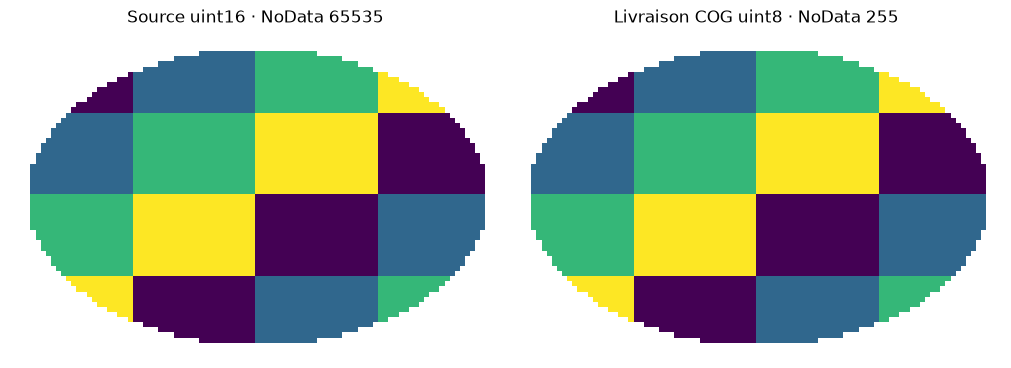

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, data, title in zip(axes, [before_values, after_values],
                           ["Source uint16 · NoData 65535", "Livraison COG uint8 · NoData 255"]):
    ax.imshow(data, cmap="viridis", vmin=0, vmax=3, interpolation="nearest")
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## 5. Une conversion impossible doit être refusée

Une valeur 300 ne tient pas dans `uint8`. Elle ne doit ni être tronquée à 255 ni revenir à 44. Le contrôle de plage reste obligatoire, même si une perte de précision a été acceptée par `loss_policy="report"`.

In [7]:
wide = write_raster(out / "valeur_300.tif", np.array([[0, 300]], dtype="uint16"))
try:
    cm.convert_raster(wide, out / "refus", dtype="uint8")
except ValueError as exc:
    print("Refus attendu :", str(exc))
else:
    raise AssertionError("La valeur 300 a été acceptée à tort dans uint8.")
assert not (out / "refus").exists()

Refus attendu : Raster values overflow the requested integer dtype; clipping is never implicit.


## 6. Le même traitement dans un plan

Le produit nommé `data` peut alimenter l’étape suivante. Les manifestes et rapports suivent les déplacements entre dossiers temporaires et livraison finale.

In [8]:
plan = cm.processing_plan([
    {"id": "livraison", "operation": "raster.convert", "parameters": {
        "source": str(raster_source), "driver": "GTiff", "dtype": "uint8", "nodata": 255}},
    {"id": "cog", "operation": "raster.convert", "parameters": {
        "source": "@livraison:data", "driver": "COG", "compression": "deflate"}},
])
manifest = cm.run_plan(plan, out / "plan")
plan_result = json.loads(Path(manifest).read_text(encoding="utf-8"))
products = plan_result["products"]["cog"]
assert all(Path(path).is_file() for path in products.values())
with rasterio.open(products["data"]) as saved:
    np.testing.assert_array_equal(saved.read(1, masked=True), after_values)
print("Plan vérifié :", ", ".join(products))

Plan vérifié : primary, data, manifest, report


## 7. Réutiliser le parcours

Dans la fenêtre, ouvrir **Projet → Conversion et formats**, sélectionner la source, analyser ses couches ou bandes, puis choisir le format et un dossier neuf. Les mêmes contrôles s’appliquent. Le rapport reste accessible depuis les résultats.

**Exercice :** refaire la conversion raster avec `nodata=None`. Vérifier que le NoData déclaré disparaît mais que les pixels invalides restent masqués. Une valeur valide égale à zéro doit rester valide. Le dossier de livraison doit conserver les fichiers associés indiqués par le manifeste.

In [9]:
without_nodata = cm.convert_raster(raster_source, out / "masque_seul", nodata=None)
with rasterio.open(raster_source) as before, rasterio.open(without_nodata.data) as after:
    assert after.nodata is None
    np.testing.assert_array_equal(before.read_masks(), after.read_masks())
    zero = (before.read(1) == 0) & (before.read_masks(1) > 0)
    assert zero.any() and np.all(after.read_masks(1)[zero] > 0)
print("NoData retiré, masque conservé, zéros valides préservés.")

NoData retiré, masque conservé, zéros valides préservés.
